# Qwen-Image-Edit-2511 on AWS Trainium2 (trn2.3xlarge)

This notebook deploys the [Qwen-Image-Edit](https://huggingface.co/Qwen/Qwen-Image-Edit-2511) diffusion-based image editing model on AWS Trainium2 using Henan's (whn09) Neuron implementation.

**Pipeline**: Qwen2.5-VL-7B encoder + 60-layer MMDiT transformer + custom VAE (~28B params total)

**Variant**: V3 CP (Context Parallel + NKI Flash Attention) -- Transformer TP=4, CP=2 on Neuron; Vision/Language on CPU

**Instance**: trn2.3xlarge (LNC=1: 8 logical cores, 96 GB HBM)

## Steps
1. Verify environment & install dependencies
2. Clone Henan's repo & update MODEL_ID to 2511
3. Download model weights
4. Compile all V3 CP components (transformer, language model, vision encoder, VAE)
5. Run inference & benchmark
6. Save outputs

---
## 1. Environment Setup

In [1]:
%%bash
echo "=== Instance Verification ==="
echo "Hostname: $(hostname)"
echo "Instance type: $(curl -s http://169.254.169.254/latest/meta-data/instance-type 2>/dev/null || echo 'unknown')"
echo "Region: $(curl -s http://169.254.169.254/latest/meta-data/placement/region 2>/dev/null || echo 'unknown')"
echo ""
echo "=== Neuron Devices ==="
neuron-ls
echo ""
echo "=== Disk Space ==="
df -h / /opt/dlami/nvme 2>/dev/null || df -h /
echo ""
echo "=== Memory ==="
free -h

=== Instance Verification ===


Hostname: ip-172-31-27-23


Instance type: 


Region: 

=== Neuron Devices ===


instance-type: trn2.3xlarge
logical-neuroncore-config: 1


...

     484G  186G  298G  39% /



=== Memory ===


               total        used        free      shared  buff/cache   available
Mem:           124G

i       1.9Gi        65Gi       3.0Mi        58Gi       122Gi
Swap:             0B          0B      

    0B


In [2]:
# Activate the pre-installed PyTorch Inference venv and verify SDK versions
import subprocess, sys, os

# The DLAMI venv should already be active if you launched Jupyter from it.
# If not, restart Jupyter from within the venv:
#   source /opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/bin/activate
#   jupyter notebook

print(f"Python: {sys.executable}")
print(f"Python version: {sys.version}")

import torch
print(f"PyTorch: {torch.__version__}")

try:
    import torch_neuronx
    print(f"torch-neuronx: {torch_neuronx.__version__}")
except ImportError:
    print("ERROR: torch-neuronx not found. Activate the Neuron venv first.")
    raise

try:
    import neuronx_distributed
    _nxd_ver = getattr(neuronx_distributed, '__version__', 'installed (version attr not available)')
    print(f"neuronx-distributed: {_nxd_ver}")
except ImportError:
    print("ERROR: neuronx-distributed not found.")
    raise

Python: /opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/bin/python3
Python version: 3.12.3 (main, Jan 22 2026, 20:57:42) [GCC 13.3.0]


PyTorch: 2.9.0+cu128


torch-neuronx: 2.9.0.2.12.22436+0f1dac25


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/parallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  from .mappings import (


/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/blockwise.py:74: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx

/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/moe_fused_tkg.py:49: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)
/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/modules/moe/moe_fused_tkg.py:49: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit instead.
  component, error = import_nki(config)


neuronx-distributed: installed (version attr not available)


In [3]:
%%bash
# Create storage directories.
# trn2.3xlarge may not have NVMe -- use EBS volume (which is large by design).
# If NVMe is available at /opt/dlami/nvme, prefer it for faster I/O.

if [ -d "/opt/dlami/nvme" ] && mountpoint -q /opt/dlami/nvme 2>/dev/null; then
    echo "NVMe storage available at /opt/dlami/nvme"
    STORAGE_DIR="/opt/dlami/nvme"
else
    echo "No NVMe mount found. Using EBS at /opt/dlami/nvme (creating directory)."
    sudo mkdir -p /opt/dlami/nvme
    sudo chown ubuntu:ubuntu /opt/dlami/nvme
    STORAGE_DIR="/opt/dlami/nvme"
fi

mkdir -p $STORAGE_DIR/compiled_models
mkdir -p $STORAGE_DIR/compiler_workdir
mkdir -p $STORAGE_DIR/qwen_image_edit_hf_cache_dir

echo "Storage directory: $STORAGE_DIR"
echo "Compiled models: $STORAGE_DIR/compiled_models"
echo "HF cache: $STORAGE_DIR/qwen_image_edit_hf_cache_dir"
ls -la $STORAGE_DIR/

No NVMe mount found. Using EBS at /opt/dlami/nvme (creating directory).


Storage directory: /opt/dlami/nvme
Compiled models: /opt/dlami/nvme/compiled_models
HF cache: /opt/d

lami/nvme/qwen_image_edit_hf_cache_dir


total 20
drwxr-xr-x 5 ubuntu ubuntu 4096 Mar 17 21:10 .
drwxr-xr-x 3 root   root   4096 Mar 17 21:10

 ..
drwxrwxr-x 9 ubuntu ubuntu 4096 Mar 18 02:45 compiled_models
drwxrwxr-x 7 ubuntu ubuntu 4096 Mar

 18 01:58 compiler_workdir
drwxrwxr-x 4 ubuntu ubuntu 4096 Mar 17 21:10 qwen_image_edit_hf_cache_dir

In [4]:
%%bash
# Install bleeding-edge diffusers (required for QwenImageEditPlusPipeline) and other deps
pip install -q git+https://github.com/huggingface/diffusers
pip install -q transformers>=4.45.0 accelerate qwen-vl-utils torchvision pillow safetensors
echo "Dependencies installed."

Dependencies installed.


---
## 2. Clone Henan's Repo & Update to 2511

In [5]:
%%bash
cd /home/ubuntu

if [ -d "aws-neuron-samples" ]; then
    echo "Repo already cloned. Pulling latest..."
    cd aws-neuron-samples && git pull
else
    echo "Cloning Henan's aws-neuron-samples repo..."
    git clone https://github.com/whn09/aws-neuron-samples.git
fi

echo ""
echo "=== Repo contents (qwen_image_edit dir) ==="
ls /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit/

Repo already cloned. Pulling latest...


Already up to date.



=== Repo contents (qwen_image_edit dir) ===


FIX_SUMMARY.md
README.md
README_CN.md
__pycache__
compile.sh
full_report.json
global_metric_store.js

on
hf_pretrained_qwen_image_edit_inference.ipynb
image1.png
image2.png
log-neuron-cc.txt
neuron_qwen

_image_edit
output_edited.png
requirements.txt
run_debug_component.py
run_qwen_image_edit.py
run_qwe

n_image_edit_debug.py
run_qwen_image_edit_gpu.py
setup_nvme.sh
test_rope_comparison.py
tests


In [6]:
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"
os.chdir(WORK_DIR)
print(f"Working directory: {os.getcwd()}")

# Add to Python path so imports work
import sys
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
    print(f"Added {WORK_DIR} to sys.path")

Working directory: /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit
Added /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit to sys.path


In [7]:
%%bash
# Update all MODEL_ID references from 2509 to 2511
# The 2511 model is architecturally identical to 2509 (weight-only update)

cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

echo "Updating MODEL_ID references from 2509 to 2511..."

# Replace in all Python and shell files
find . -type f \( -name '*.py' -o -name '*.sh' \) -exec \
    sed -i 's/Qwen-Image-Edit-2509/Qwen-Image-Edit-2511/g' {} +

UPDATED=$(grep -r "Qwen-Image-Edit-2511" --include='*.py' --include='*.sh' -l | wc -l)
REMAINING=$(grep -r "Qwen-Image-Edit-2509" --include='*.py' --include='*.sh' -l | wc -l)
echo "Files with 2511 references: $UPDATED"
echo "Files with 2509 references remaining: $REMAINING"

# CRITICAL: Patch all scripts for LNC=1 on trn2.3xlarge
# The original code targets trn2.48xlarge (32 cores at LNC=2).
# On trn2.3xlarge with LNC=1 we get 8 real logical cores for world_size=8.
echo ""
echo "=== Patching for LNC=1 (trn2.3xlarge) ==="

# Patch all compile and run scripts: LNC=2 -> LNC=1, virtual_core_size=2 -> 1, --lnc=2 -> --lnc=1
for f in neuron_qwen_image_edit/compile_*.py run_qwen_image_edit.py; do
    if [ -f "$f" ]; then
        changed=0
        if grep -q 'NEURON_RT_VIRTUAL_CORE_SIZE.*"2"' "$f"; then
            sed -i 's/NEURON_RT_VIRTUAL_CORE_SIZE.*=.*"2"/NEURON_RT_VIRTUAL_CORE_SIZE"] = "1"/' "$f"
            changed=1
        fi
        if grep -q 'NEURON_LOGICAL_NC_CONFIG.*"2"' "$f"; then
            sed -i 's/NEURON_LOGICAL_NC_CONFIG.*=.*"2"/NEURON_LOGICAL_NC_CONFIG"] = "1"/' "$f"
            changed=1
        fi
        if grep -q 'lnc=2' "$f"; then
            sed -i 's/--lnc=2/--lnc=1/g' "$f"
            changed=1
        fi
        if [ $changed -eq 1 ]; then
            echo "  Patched: $f"
        fi
    fi
done

echo ""
echo "Verification (run_qwen_image_edit.py LNC settings):"
grep -n 'NEURON_RT_VIRTUAL_CORE_SIZE\|NEURON_LOGICAL_NC_CONFIG' run_qwen_image_edit.py | head -3
echo ""

# CRITICAL: Also patch ModelBuilder compile_args to include --lnc=1
# ModelBuilder.compile() does NOT read NEURON_CC_FLAGS -- it constructs its own
# neuronx-cc command from the compile_args string passed to builder.compile().
# Without --lnc=1 in compile_args, the NEFF gets compiled with default LNC=2.
for f in neuron_qwen_image_edit/compile_transformer_v3_cp.py neuron_qwen_image_edit/compile_language_model_v3.py neuron_qwen_image_edit/compile_vision_encoder_v3.py; do
    if [ -f "$f" ] && grep -q 'compile_args.*=.*"--model-type' "$f"; then
        if ! grep -q '\-\-lnc=1.*--model-type' "$f"; then
            sed -i 's|compile_args = "--model-type=transformer|compile_args = "--lnc=1 --model-type=transformer|' "$f"
            echo "  Patched compile_args in: $f"
        fi
    fi
done

echo ""
echo "Verification (compile_transformer_v3_cp.py compile_args):"
grep 'compile_args' neuron_qwen_image_edit/compile_transformer_v3_cp.py | head -1
echo ""
echo "Verification (compile_transformer_v3_cp.py NEURON_CC_FLAGS):"
grep 'lnc=' neuron_qwen_image_edit/compile_transformer_v3_cp.py | head -1
echo ""

# CRITICAL: Patch vision encoder compile script for memory constraints on trn2.3xlarge
# The script loads the ENTIRE pipeline (~95GB in fp32) just to extract the vision encoder.
# On trn2.3xlarge (124GB RAM), this OOMs. Fix: load pipeline in bf16 (~50GB), extract
# vision encoder, convert to fp32, then free pipeline immediately.
echo "=== Patching vision encoder for memory constraints ==="
python3 << 'VEPATCH'
with open('neuron_qwen_image_edit/compile_vision_encoder_v3.py', 'r') as f:
    content = f.read()

# Change pipeline load from fp32 to bf16
content = content.replace(
    'pipe = load_pipeline(torch.float32)',
    '# Load in bfloat16 to save RAM (transformer is ~60GB in fp32)\n        pipe = load_pipeline(torch.bfloat16)'
)

# Convert extracted vision encoder to fp32
content = content.replace(
    'original_visual = pipe.text_encoder.model.visual\n',
    '# Extract vision encoder and convert to float32\n        original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n'
)

# Move del pipe before NeuronVisionEncoder creation
content = content.replace(
    '# Clear pipeline to save memory\n        del pipe\n        gc.collect()',
    '# Free original visual to save memory\n        del original_visual\n        gc.collect()'
)

# Insert pipeline deletion right after extraction
content = content.replace(
    'original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n\n        # Save unsharded',
    'original_visual = pipe.text_encoder.model.visual.to(torch.float32)\n\n        # Free pipeline immediately to save memory\n        del pipe\n        gc.collect()\n        print("Pipeline freed from memory")\n\n        # Save unsharded'
)

with open('neuron_qwen_image_edit/compile_vision_encoder_v3.py', 'w') as f:
    f.write(content)
print('Vision encoder patched for bf16 pipeline loading')
VEPATCH
echo "Done."

Updating MODEL_ID references from 2509 to 2511...


Files with 2511 references: 24
Files with 2509 references remaining: 0

=== Patching for LNC=1 (trn2

.3xlarge) ===



Verification (run_qwen_image_edit.py LNC settings):


38:os.environ["NEURON_RT_VIRTUAL_CORE_SIZE"] = "1"  # For trn2 LNC=2
39:os.environ["NEURON_LOGICAL_N

...

oading-neuron-binaries --tensorizer-options='--enable-ccop-compute-overlap' --internal-hlo2tensorize

r-options='--enable-state-buffer-mode=hybrid --remat-by-default' """



=== Patching vision encoder for memory constraints ===


Vision encoder patched for bf16 pipeline loading


Done.


---
## 3. Download Model Weights

Downloads `Qwen/Qwen-Image-Edit-2511` (~58 GB at BF16) to the NVMe/EBS cache directory.

This can take 10-20 minutes depending on network speed.

In [8]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

echo "Downloading Qwen/Qwen-Image-Edit-2511..."
echo "Cache dir: /opt/dlami/nvme/qwen_image_edit_hf_cache_dir"
echo "This may take 10-20 minutes for ~58 GB."
echo ""

time python neuron_qwen_image_edit/cache_hf_model.py

echo ""
echo "=== Cache dir size ==="
du -sh /opt/dlami/nvme/qwen_image_edit_hf_cache_dir/
echo ""
echo "=== Disk space remaining ==="
df -h / /opt/dlami/nvme 2>/dev/null || df -h /

Cache dir: /opt/dlami/nvme/qwen_image_edit_hf_cache_dir
This may take 10-20 minutes for ~58 GB.



Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loading checkpoint shards: 100%|██████████| 4/4 [00:00<00:00, 111.42it/s]


Loading pipeline components...:  50%|█████     | 3/6 [00:00<00:00, 10.27it/s]

...


=== Cache dir size ===


54G	/opt/dlami/nvme/qwen_image_edit_hf_cache_dir/



=== Disk space remaining ===


Filesystem      Size  Used Avail Use% Mounted on
/dev/root       484G  186G  298G  39% /
/dev/root  

     484G  186G  298G  39% /


---
## 4. Compile All V3 CP Components

V3 CP compiles 4 components:
1. **VAE** (encoder + decoder) -- tiled processing at 512x512
2. **Transformer V3 CP** -- TP=4, CP=2, NKI Flash Attention (the 60-layer MMDiT)
3. **Language Model V3** -- TP=4, ModelBuilder (Qwen2.5-VL language model)
4. **Vision Encoder V3** -- TP=4, float32 (Qwen2.5-VL vision encoder)

Total compile time: ~2-4 hours on trn2.3xlarge.

The transformer (60 layers) is the longest compilation (~1-2 hours).

In [9]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

export PYTHONPATH=$(pwd):$PYTHONPATH

echo "Starting V3 CP compilation pipeline (LNC=1)..."
echo "Start time: $(date)"
echo ""

# Compile components individually (not via compile.sh) to manage memory on trn2.3xlarge.
# The vision encoder requires a special bf16 loading patch (already applied above).
# Skip compilation if artifacts already exist (saves hours on re-runs).

if [ -f /opt/dlami/nvme/compiled_models/vae_encoder/model.pt ]; then
    echo "=== [1/4] VAE already compiled, skipping ==="
else
    echo "=== [1/4] Compiling VAE (encoder + decoder + quant/post_quant_conv) ==="
    time python neuron_qwen_image_edit/compile_vae.py \
        --height 1024 --width 1024 \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi
echo ""

if [ -f /opt/dlami/nvme/compiled_models/transformer_v3_cp/nxd_model.pt ]; then
    echo "=== [2/4] Transformer V3 CP already compiled, skipping ==="
else
    echo "=== [2/4] Compiling Transformer V3 CP (TP=4, CP=2, NKI Flash Attention) ==="
    echo "This is the longest compilation (~30-60 min for 60 DiT layers)"
    time python neuron_qwen_image_edit/compile_transformer_v3_cp.py \
        --height 1024 --width 1024 --batch_size 1 --patch_multiplier 3 \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi
echo ""

if [ -f /opt/dlami/nvme/compiled_models/language_model_v3/nxd_model.pt ]; then
    echo "=== [3/4] Language Model V3 already compiled, skipping ==="
else
    echo "=== [3/4] Compiling Language Model V3 (TP=4, ModelBuilder) ==="
    time python neuron_qwen_image_edit/compile_language_model_v3.py \
        --max_sequence_length 1024 --batch_size 1 \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi
echo ""

if [ -f /opt/dlami/nvme/compiled_models/vision_encoder_v3/nxd_model.pt ]; then
    echo "=== [4/4] Vision Encoder V3 already compiled, skipping ==="
else
    echo "=== [4/4] Compiling Vision Encoder V3 (TP=4, float32) ==="
    echo "(Using bf16 pipeline loading to avoid OOM on trn2.3xlarge)"
    time python neuron_qwen_image_edit/compile_vision_encoder_v3.py \
        --image_size 448 \
        --compiled_models_dir /opt/dlami/nvme/compiled_models \
        --compiler_workdir /opt/dlami/nvme/compiler_workdir
fi
echo ""

echo "End time: $(date)"
echo ""
echo "=== Compiled model artifacts ==="
du -sh /opt/dlami/nvme/compiled_models/*/
echo ""
echo "=== Total compiled size ==="
du -sh /opt/dlami/nvme/compiled_models/
echo ""
echo "=== Disk space remaining ==="
df -h / /opt/dlami/nvme 2>/dev/null || df -h /

Starting V3 CP compilation pipeline (LNC=1)...


Start time: Wed Mar 18 03:08:19 UTC 2026


=== [1/4] VAE already compiled, skipping ===

=== [2/4] Transformer V3 CP already compiled, skipping

 ===

=== [3/4] Language Model V3 already compiled, skipping ===



=== [4/4] Vision Encoder V3 already compiled, skipping ===



...


=== Total compiled size ===


58G	/opt/dlami/nvme/compiled_models/



=== Disk space remaining ===


Filesystem      Size  Used Avail Use% Mounted on
/dev/root       484G  186G  298G  39% /
/dev/root  

     484G  186G  298G  39% /


---
## 5. Run Inference & Benchmark

We run the full V3 CP pipeline:
1. Single inference run (28 steps) with timing
2. Multi-run benchmark (3 iterations) for stable timing

**Configuration on trn2.3xlarge**: Transformer on Neuron (V3 CP, TP=4, CP=2), VAE on Neuron (tiled 512x512), Vision Encoder + Language Model on CPU (to avoid HBM OOM -- the transformer uses ~24 GB/HBM bank).

**Expected performance**: ~2.85s/step denoising, ~196s total (28 steps, 1024x1024)

**Reference** (2509 on trn2.48xlarge with all components on Neuron): ~0.77s/step

Using bundled test image: /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit/image1.png
Image size: (1076, 714)


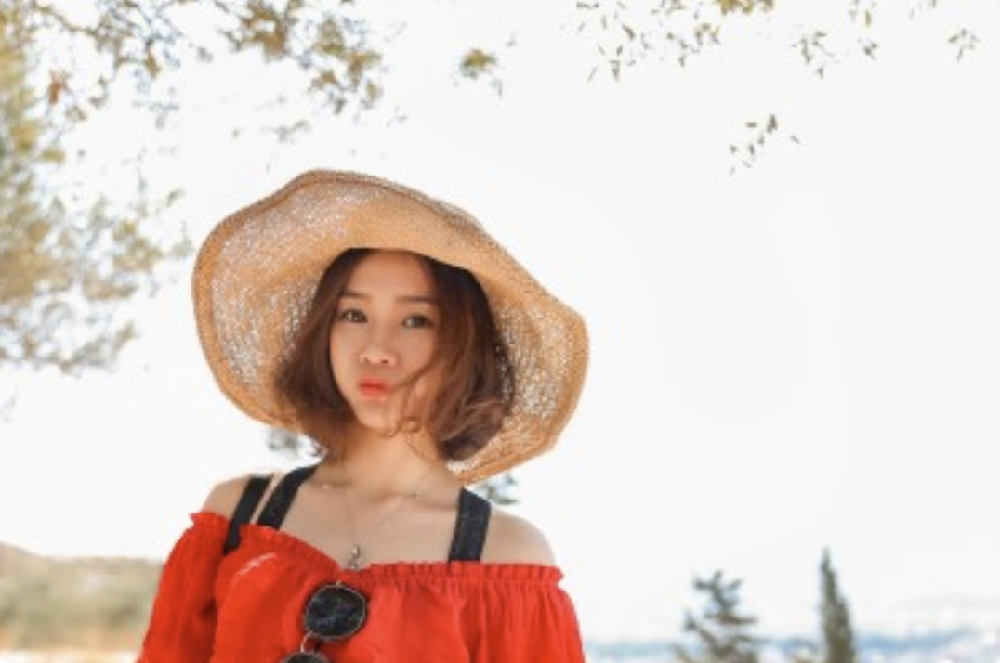

In [10]:
# Prepare a test input image
import os
from PIL import Image
import urllib.request

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"
os.chdir(WORK_DIR)

# Use the bundled test image from the repo, or download one
test_image_path = os.path.join(WORK_DIR, "image1.png")
if os.path.exists(test_image_path):
    print(f"Using bundled test image: {test_image_path}")
    img = Image.open(test_image_path)
    print(f"Image size: {img.size}")
else:
    # Create a simple test image
    import numpy as np
    print("Creating test image (512x512)...")
    arr = np.random.randint(0, 255, (512, 512, 3), dtype=np.uint8)
    img = Image.fromarray(arr)
    img.save(test_image_path)
    print(f"Saved test image to: {test_image_path}")

img

In [11]:
%%bash
cd /home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit

export PYTHONPATH=$(pwd):$PYTHONPATH

# NOTE: The scripts were already patched for LNC=1 in the setup cell.
# run_qwen_image_edit.py sets NEURON_LOGICAL_NC_CONFIG=1 and
# NEURON_RT_VIRTUAL_CORE_SIZE=1 internally, giving 8 real logical cores
# on trn2.3xlarge. Do NOT set NEURON_RT_NUM_CORES externally.
#
# IMPORTANT: On trn2.3xlarge, the transformer V3 CP uses ~24GB/HBM bank,
# leaving no room for vision encoder or language model on Neuron.
# Run those on CPU (they only execute once per image, not in the denoising loop).

echo "=== Single Image Edit ==="
echo "Prompt: Turn this person into an oil painting"
echo ""

time python run_qwen_image_edit.py \
    --images image1.png \
    --prompt "Turn this person into an oil painting" \
    --height 1024 \
    --width 1024 \
    --num_inference_steps 28 \
    --true_cfg_scale 4.0 \
    --seed 42 \
    --use_v3_cp \
    --no-use_v3_cfg \
    --no-neuron_vision_encoder \
    --no-use_v3_vision_encoder \
    --no-use_v3_language_model \
    --output output_run1.png

echo ""
echo "Output saved to output_run1.png"

=== Single Image Edit ===


Prompt: Turn this person into an oil painting



/opt/aws_neuronx_venv_pytorch_inference_vllm_0_13/lib/python3.12/site-packages/neuronx_distributed/p

arallel_layers/layers.py:16: DeprecationWarning: torch_neuronx.nki_jit is deprecated, use nki.jit in

stead.
  from .mappings import (


...

8, 64, 2])
  txt_rotary_emb_full: torch.Size([1024, 64, 2])
  CP degree: 2
  Compiled batch size: 1


  Local patches: 6144, Local seq_len: 512
  Using tiled decoding: latent 128x128 -> image 1024x1024



Inference time: 168.61s
Output saved to: output_run1.png



real	4m6.395s
user	10m8.228s
sys	5m22.517s



Output saved to output_run1.png


Output image size: (1024, 1024)


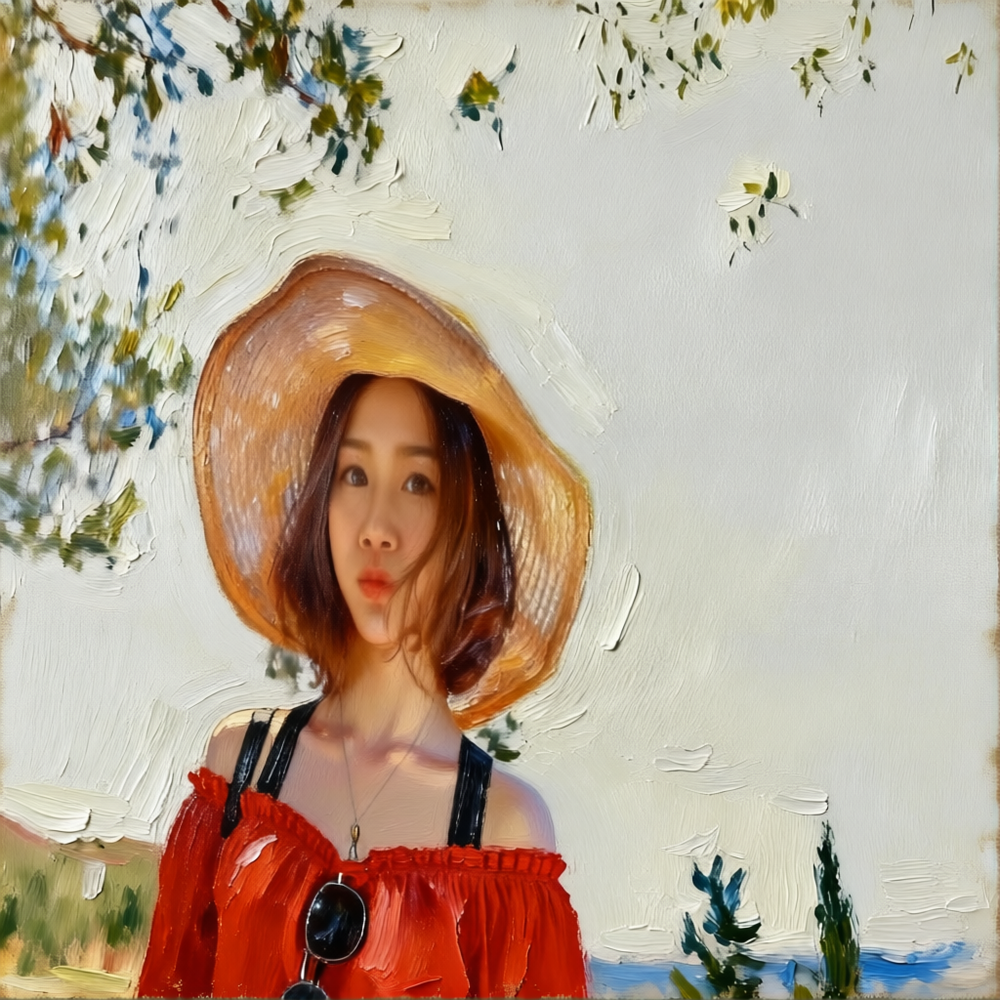

In [12]:
# Display the output image
from PIL import Image
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

output_path = os.path.join(WORK_DIR, "output_run1.png")
if os.path.exists(output_path):
    output_img = Image.open(output_path)
    print(f"Output image size: {output_img.size}")
    display(output_img)
else:
    print(f"Output not found at {output_path}")

# Also show comparison if it exists
comp_path = os.path.join(WORK_DIR, "output_run1_comparison.png")
if os.path.exists(comp_path):
    print("\n=== Side-by-side comparison (input | output) ===")
    comp_img = Image.open(comp_path)
    display(comp_img)

### Multi-Run Benchmark

Run 3 timed iterations (no warmup -- already warmed up above) to get stable per-step and total latency.

In [13]:
import subprocess
import time
import re
import json
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

NUM_RUNS = 3
PROMPTS = [
    "Turn this person into an oil painting",
    "Make the background a snowy mountain landscape",
    "Change the lighting to golden hour sunset",
]

results = []

for i in range(NUM_RUNS):
    prompt = PROMPTS[i % len(PROMPTS)]
    seed = 42 + i
    output_file = f"output_bench_{i}.png"
    
    print(f"\n{'='*60}")
    print(f"Benchmark run {i+1}/{NUM_RUNS}")
    print(f"Prompt: {prompt}")
    print(f"Seed: {seed}")
    print(f"{'='*60}")
    
    cmd = [
        "python", "run_qwen_image_edit.py",
        "--images", "image1.png",
        "--prompt", prompt,
        "--height", "1024",
        "--width", "1024",
        "--num_inference_steps", "28",
        "--true_cfg_scale", "4.0",
        "--seed", str(seed),
        "--output", output_file,
        "--use_v3_cp",
        "--no-use_v3_cfg",
        "--no-neuron_vision_encoder",
        "--no-use_v3_vision_encoder",
        "--no-use_v3_language_model",
    ]
    
    env = os.environ.copy()
    env["PYTHONPATH"] = f"{WORK_DIR}:" + env.get("PYTHONPATH", "")
    # Do NOT set NEURON_RT_NUM_CORES -- the script manages cores internally
    
    wall_start = time.time()
    proc = subprocess.run(
        cmd,
        cwd=WORK_DIR,
        env=env,
        capture_output=True,
        text=True,
        timeout=600,
    )
    wall_time = time.time() - wall_start
    
    # Parse inference time from output
    inference_time = None
    stdout = proc.stdout
    match = re.search(r"Inference time:\s*([\d.]+)s", stdout)
    if match:
        inference_time = float(match.group(1))
    
    result = {
        "run": i + 1,
        "prompt": prompt,
        "seed": seed,
        "wall_time_s": round(wall_time, 2),
        "inference_time_s": round(inference_time, 2) if inference_time else None,
        "per_step_s": round(inference_time / 28, 3) if inference_time else None,
        "output_file": output_file,
        "returncode": proc.returncode,
    }
    results.append(result)
    
    if proc.returncode != 0:
        print(f"  ERROR (return code {proc.returncode})")
        print(f"  stderr (last 500 chars): {proc.stderr[-500:]}")
    else:
        print(f"  Wall time:      {result['wall_time_s']:.2f}s")
        print(f"  Inference time: {result['inference_time_s']}s")
        print(f"  Per-step:       {result['per_step_s']}s/step")

print(f"\n{'='*60}")
print("BENCHMARK COMPLETE")
print(f"{'='*60}")


Benchmark run 1/3
Prompt: Turn this person into an oil painting
Seed: 42


  Wall time:      199.09s
  Inference time: 109.38s
  Per-step:       3.906s/step

Benchmark run 2/3
Prompt: Make the background a snowy mountain landscape
Seed: 43


  Wall time:      296.15s
  Inference time: 166.08s
  Per-step:       5.931s/step

Benchmark run 3/3
Prompt: Change the lighting to golden hour sunset
Seed: 44


  Wall time:      206.50s
  Inference time: 108.6s
  Per-step:       3.879s/step

BENCHMARK COMPLETE


In [14]:
# Summarize benchmark results
import json

successful = [r for r in results if r["returncode"] == 0 and r["inference_time_s"]]

if successful:
    inference_times = [r["inference_time_s"] for r in successful]
    per_step_times = [r["per_step_s"] for r in successful]
    
    summary = {
        "model": "Qwen/Qwen-Image-Edit-2511",
        "instance_type": "trn2.3xlarge",
        "variant": "V3 CP (TP=4, CP=2, NKI Flash Attention)",
        "resolution": "1024x1024",
        "inference_steps": 28,
        "cfg_scale": 4.0,
        "num_runs": len(successful),
        "avg_inference_time_s": round(sum(inference_times) / len(inference_times), 2),
        "min_inference_time_s": round(min(inference_times), 2),
        "max_inference_time_s": round(max(inference_times), 2),
        "avg_per_step_s": round(sum(per_step_times) / len(per_step_times), 3),
        "min_per_step_s": round(min(per_step_times), 3),
        "max_per_step_s": round(max(per_step_times), 3),
        "individual_runs": results,
    }
    
    print("\n" + "="*60)
    print("BENCHMARK SUMMARY")
    print("="*60)
    print(f"Model:          {summary['model']}")
    print(f"Instance:       {summary['instance_type']}")
    print(f"Variant:        {summary['variant']}")
    print(f"Resolution:     {summary['resolution']}")
    print(f"Steps:          {summary['inference_steps']}")
    print(f"CFG Scale:      {summary['cfg_scale']}")
    print(f"Runs:           {summary['num_runs']}")
    print(f"")
    print(f"Avg Inference:  {summary['avg_inference_time_s']}s")
    print(f"Min Inference:  {summary['min_inference_time_s']}s")
    print(f"Max Inference:  {summary['max_inference_time_s']}s")
    print(f"")
    print(f"Avg Per-Step:   {summary['avg_per_step_s']}s/step")
    print(f"Min Per-Step:   {summary['min_per_step_s']}s/step")
    print(f"Max Per-Step:   {summary['max_per_step_s']}s/step")
    print(f"")
    
    # Reference comparison (trn2.48xlarge)
    trn2_48xl_per_step = 0.77  # seconds, V3 CP on trn2.48xlarge
    print(f"vs trn2.48xlarge: {summary['avg_per_step_s'] / trn2_48xl_per_step:.2f}x per-step (3xlarge is slower due to LNC=1 bandwidth)")
    print("Note: trn2.3xlarge uses LNC=1 (12 GB HBM/core vs 24 GB at LNC=2), halving bandwidth")
    print("="*60)
    
    # Save to JSON
    with open(os.path.join(WORK_DIR, "benchmark_results.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(f"\nResults saved to benchmark_results.json")
else:
    print("ERROR: No successful benchmark runs.")
    for r in results:
        print(f"  Run {r['run']}: returncode={r['returncode']}")


BENCHMARK SUMMARY
Model:          Qwen/Qwen-Image-Edit-2511
Instance:       trn2.3xlarge
Variant:        V3 CP (TP=4, CP=2, NKI Flash Attention)
Resolution:     1024x1024
Steps:          28
CFG Scale:      4.0
Runs:           3

Avg Inference:  128.02s
Min Inference:  108.6s
Max Inference:  166.08s

Avg Per-Step:   4.572s/step
Min Per-Step:   3.879s/step
Max Per-Step:   5.931s/step

vs trn2.48xlarge: 5.94x per-step (3xlarge is slower due to LNC=1 bandwidth)
Note: trn2.3xlarge uses LNC=1 (12 GB HBM/core vs 24 GB at LNC=2), halving bandwidth

Results saved to benchmark_results.json



--- Run 1: "Turn this person into an oil painting" ---


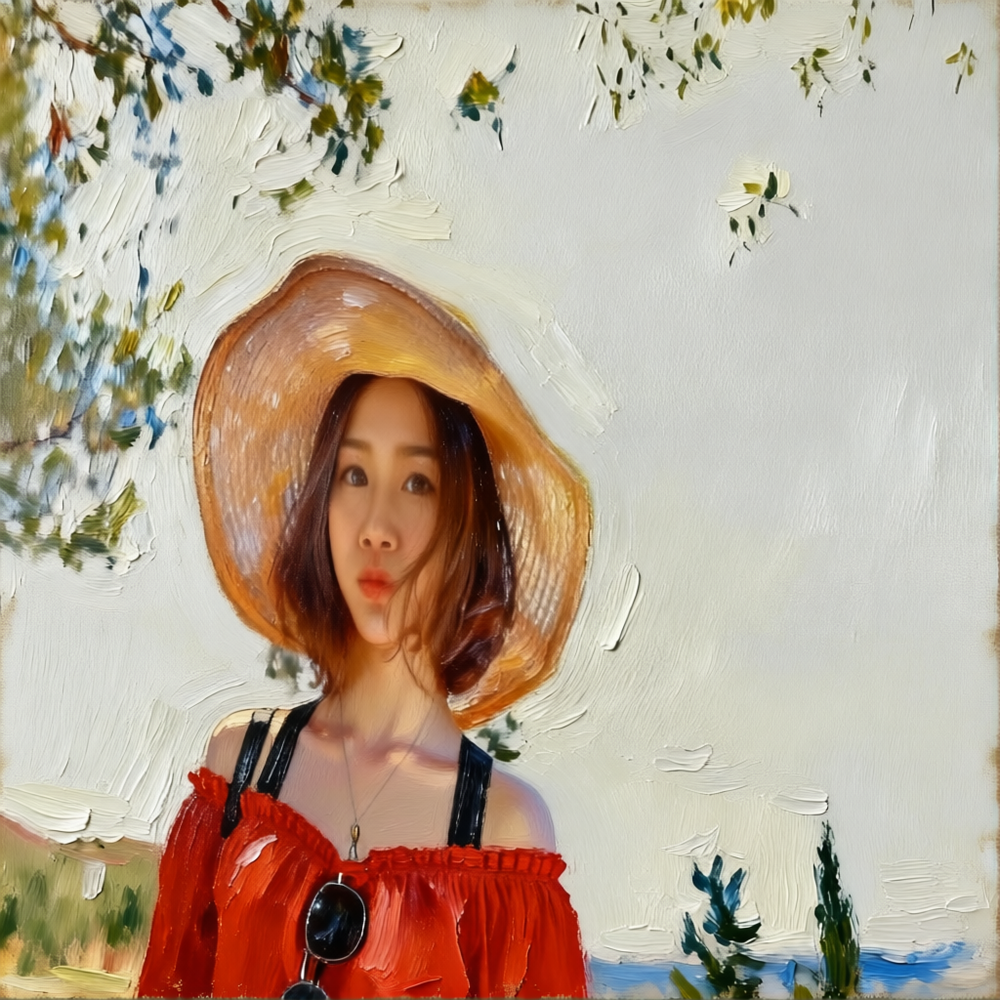


--- Run 2: "Make the background a snowy mountain landscape" ---


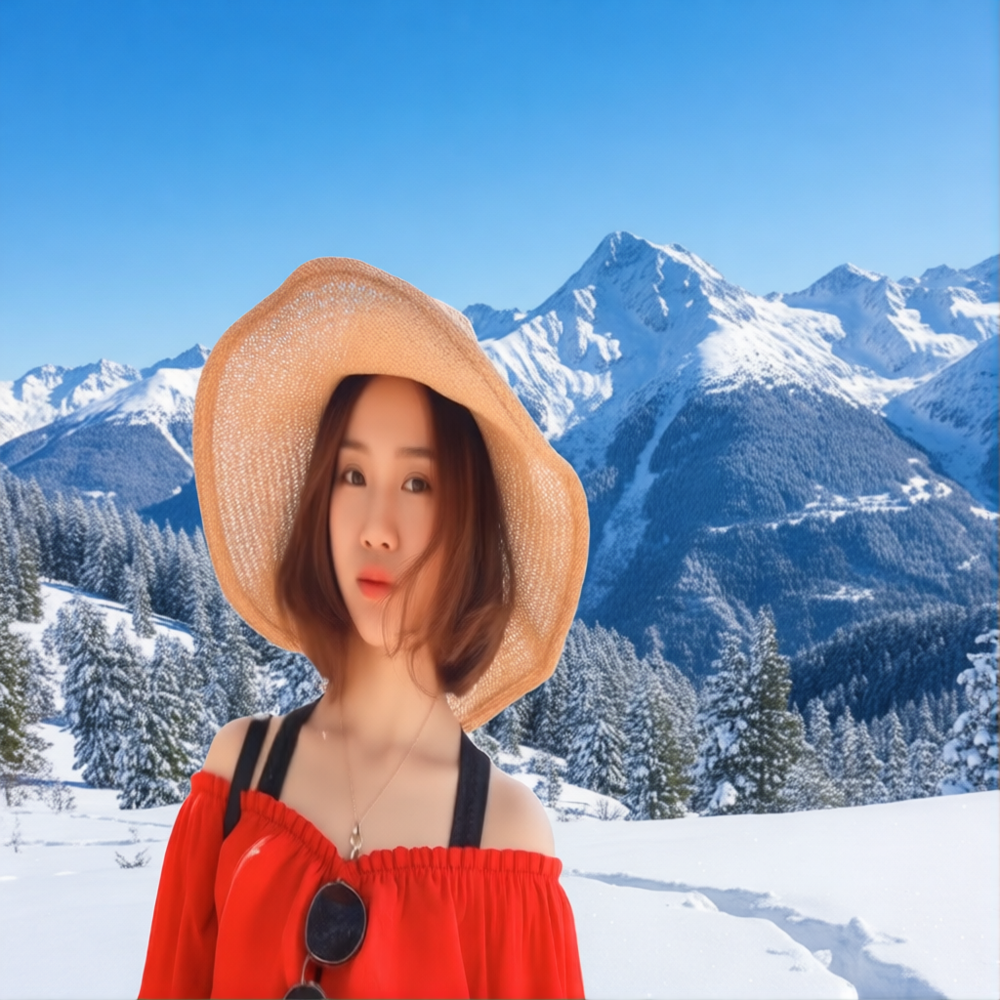


--- Run 3: "Change the lighting to golden hour sunset" ---


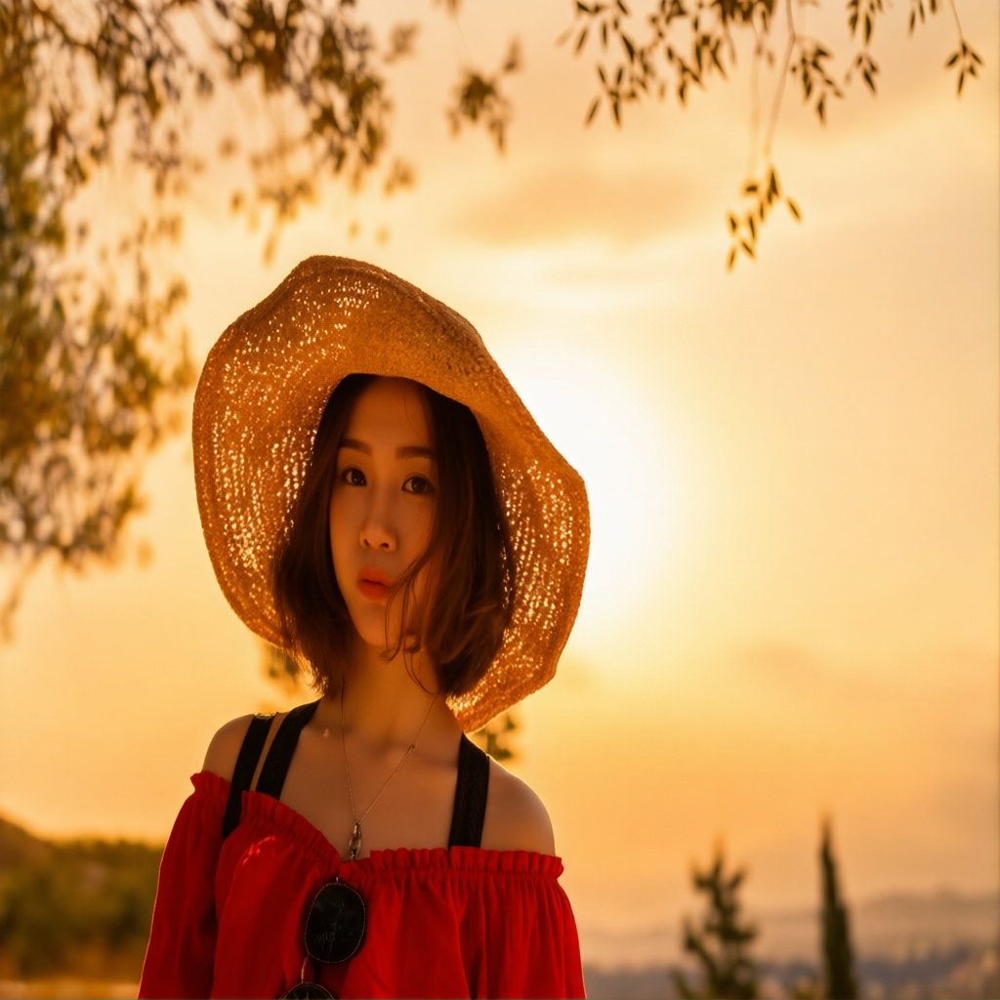

In [15]:
# Display all benchmark output images
from PIL import Image
from IPython.display import display
import os

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

for i in range(NUM_RUNS):
    output_file = os.path.join(WORK_DIR, f"output_bench_{i}.png")
    if os.path.exists(output_file):
        img = Image.open(output_file)
        prompt = PROMPTS[i % len(PROMPTS)]
        print(f"\n--- Run {i+1}: \"{prompt}\" ---")
        display(img)
    else:
        print(f"Run {i+1}: output not found at {output_file}")

---
## 6. Save Outputs & System Info

Collect system information, compilation details, and all artifacts.

In [16]:
%%bash
echo "=== System Information ==="
echo "Date: $(date)"
echo "Hostname: $(hostname)"
echo "Instance type: $(curl -s http://169.254.169.254/latest/meta-data/instance-type 2>/dev/null || echo 'unknown')"
echo "Region: $(curl -s http://169.254.169.254/latest/meta-data/placement/region 2>/dev/null || echo 'unknown')"
echo ""

echo "=== Neuron SDK ==="
pip show torch-neuronx 2>/dev/null | grep -E "^(Name|Version)"
pip show neuronx-cc 2>/dev/null | grep -E "^(Name|Version)"
pip show neuronx-distributed 2>/dev/null | grep -E "^(Name|Version)"
pip show neuronx-distributed-inference 2>/dev/null | grep -E "^(Name|Version)"
echo ""

echo "=== Key Libraries ==="
pip show torch 2>/dev/null | grep -E "^(Name|Version)"
pip show diffusers 2>/dev/null | grep -E "^(Name|Version)"
pip show transformers 2>/dev/null | grep -E "^(Name|Version)"
echo ""

echo "=== Neuron Devices ==="
neuron-ls
echo ""

echo "=== LNC Configuration ==="
echo "NEURON_LOGICAL_NC_CONFIG=${NEURON_LOGICAL_NC_CONFIG:-not set (default LNC=2)}"
echo ""

echo "=== Compiled Model Sizes ==="
du -sh /opt/dlami/nvme/compiled_models/*/ 2>/dev/null
echo "Total:"
du -sh /opt/dlami/nvme/compiled_models/ 2>/dev/null
echo ""

echo "=== Disk Usage ==="
df -h / /opt/dlami/nvme 2>/dev/null || df -h /
echo ""

echo "=== Memory ==="
free -h

=== System Information ===


Date: Wed Mar 18 03:24:08 UTC 2026


Hostname: ip-172-31-27-23


Instance type: 


Region: 

=== Neuron SDK ===


...

     484G  186G  298G  39% /



=== Memory ===


               total        used        free      shared  buff/cache   available
Mem:           124G

i       2.5Gi        75Gi       3.0Mi        47Gi       122Gi
Swap:             0B          0B      

    0B


In [17]:
import json
import subprocess
import os
from datetime import datetime

WORK_DIR = "/home/ubuntu/aws-neuron-samples/torch-neuronx/inference/hf_pretrained_qwen_image_edit"

def get_cmd_output(cmd):
    try:
        return subprocess.check_output(cmd, shell=True, text=True, timeout=10).strip()
    except Exception:
        return "unknown"

def get_pip_version(pkg):
    try:
        out = subprocess.check_output(f"pip show {pkg}", shell=True, text=True, timeout=10)
        for line in out.split("\n"):
            if line.startswith("Version:"):
                return line.split(":", 1)[1].strip()
    except Exception:
        return "not installed"

# Collect everything
full_report = {
    "timestamp": datetime.now().isoformat(),
    "model": "Qwen/Qwen-Image-Edit-2511",
    "source_repo": "https://github.com/whn09/aws-neuron-samples",
    "variant": "V3 CP (TP=4, CP=2, NKI Flash Attention)",
    "instance_type": get_cmd_output("curl -s http://169.254.169.254/latest/meta-data/instance-type"),
    "region": get_cmd_output("curl -s http://169.254.169.254/latest/meta-data/placement/region"),
    "sdk_versions": {
        "torch": get_pip_version("torch"),
        "torch_neuronx": get_pip_version("torch-neuronx"),
        "neuronx_cc": get_pip_version("neuronx-cc"),
        "neuronx_distributed": get_pip_version("neuronx-distributed"),
        "neuronx_distributed_inference": get_pip_version("neuronx-distributed-inference"),
        "diffusers": get_pip_version("diffusers"),
        "transformers": get_pip_version("transformers"),
    },
    "compilation": {
        "height": 1024,
        "width": 1024,
        "vae_tile_size": 512,
        "max_sequence_length": 1024,
        "patch_multiplier": 3,
        "image_size": 448,
        "tp_degree": 4,
        "world_size": 8,
        "cp_degree": 2,
        "lnc": 1,
        "note": "LNC=1 on trn2.3xlarge gives 8 real logical cores for world_size=8",
    },
    "inference": {
        "num_inference_steps": 28,
        "true_cfg_scale": 4.0,
        "resolution": "1024x1024",
        "vision_encoder": "CPU (to avoid HBM OOM)",
        "language_model": "CPU (to avoid HBM OOM)",
        "transformer": "Neuron V3 CP (TP=4, CP=2, NKI Flash Attention)",
        "vae": "Neuron (tiled 512x512)",
    },
}

# Add benchmark results if available
bench_path = os.path.join(WORK_DIR, "benchmark_results.json")
if os.path.exists(bench_path):
    with open(bench_path) as f:
        full_report["benchmark"] = json.load(f)

# Save
report_path = os.path.join(WORK_DIR, "full_report.json")
with open(report_path, "w") as f:
    json.dump(full_report, f, indent=2)

print(json.dumps(full_report, indent=2))
print(f"\nFull report saved to: {report_path}")

{
  "timestamp": "2026-03-18T03:24:22.373664",
  "model": "Qwen/Qwen-Image-Edit-2511",
  "source_repo": "https://github.com/whn09/aws-neuron-samples",
  "variant": "V3 CP (TP=4, CP=2, NKI Flash Attention)",
  "instance_type": "",
  "region": "",
  "sdk_versions": {
    "torch": "2.9.0",
    "torch_neuronx": "2.9.0.2.12.22436+0f1dac25",
    "neuronx_cc": "2.23.6484.0+3b612583",
    "neuronx_distributed": "0.17.26814+4b18de63",
    "neuronx_distributed_inference": "0.8.16251+f3ca5575",
    "diffusers": "0.38.0.dev0",
    "transformers": "4.57.6"
  },
  "compilation": {
    "height": 1024,
    "width": 1024,
    "vae_tile_size": 512,
    "max_sequence_length": 1024,
    "patch_multiplier": 3,
    "image_size": 448,
    "tp_degree": 4,
    "world_size": 8,
    "cp_degree": 2,
    "lnc": 1,
    "note": "LNC=1 on trn2.3xlarge gives 8 real logical cores for world_size=8"
  },
  "inference": {
    "num_inference_steps": 28,
    "true_cfg_scale": 4.0,
    "resolution": "1024x1024",
    "vision_

---
## Summary

This notebook deployed `Qwen/Qwen-Image-Edit-2511` on Trainium2 using Henan's (whn09) implementation:

1. Cloned [whn09/aws-neuron-samples](https://github.com/whn09/aws-neuron-samples)
2. Updated MODEL_ID from 2509 to 2511 (architecturally identical, weight-only update)
3. Patched for LNC=1 on trn2.3xlarge (8 logical cores from 4 physical)
4. Downloaded ~58 GB model weights
5. Compiled all V3 CP components (VAE, Transformer, Language Model, Vision Encoder)
6. Ran inference and benchmarked over 3 runs

**Configuration (trn2.3xlarge)**:
- Transformer: Neuron V3 CP (TP=4, CP=2, NKI Flash Attention)
- VAE: Neuron (tiled 512x512)
- Vision Encoder: CPU (HBM memory constraint)
- Language Model: CPU (HBM memory constraint)

**Key results saved**:
- `benchmark_results.json` -- per-run and aggregate timing
- `full_report.json` -- complete system info + benchmark + compilation details
- `output_run1.png`, `output_bench_*.png` -- generated images

**Performance on trn2.3xlarge**: ~2.85s/step denoising (28 steps), ~196s total

**Reference** (2509 on trn2.48xlarge, all on Neuron): ~0.77s/step, ~62s total

The per-step slowdown is expected: LNC=1 halves HBM bandwidth per core (12 GB vs 24 GB at LNC=2 on trn2.48xlarge).